In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive = Path("/content/drive/MyDrive/CAPSTONE DATASET")

print("Top-level folders/files in MyDrive:\n")

for p in sorted(drive.iterdir()):
    print(p)

Top-level folders/files in MyDrive:

/content/drive/MyDrive/CAPSTONE DATASET/3-10-26
/content/drive/MyDrive/CAPSTONE DATASET/DEMO_MODEL_codes
/content/drive/MyDrive/CAPSTONE DATASET/Original_Images
/content/drive/MyDrive/CAPSTONE DATASET/Original_sensor_data.xlsx
/content/drive/MyDrive/CAPSTONE DATASET/Processed_Images
/content/drive/MyDrive/CAPSTONE DATASET/feature_engineered_data
/content/drive/MyDrive/CAPSTONE DATASET/mmodels
/content/drive/MyDrive/CAPSTONE DATASET/notebooks
/content/drive/MyDrive/CAPSTONE DATASET/processed_data


In [ ]:
import pandas as pd
import numpy as np
import os

BASE = "/content/drive/MyDrive/CAPSTONE DATASET/3-10-26"

EXCEL_PATH = os.path.join(
    BASE,
    "Original_sensor_data_labeled.xlsx"
)

df = pd.read_excel(EXCEL_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (3316, 9)

Columns:
['Sl No', 'Temperature', 'Humidity', 'Gas', 'Image Path', 'Timestamp', 'Date', 'Day', 'Ripeness_Label']


,Sl No,Temperature,Humidity,Gas,Image Path,Timestamp,Date,Day,Ripeness_Label
0,1,28.74,58.04,185,/home/raspi_5/project/dataset/images/20260606_...,2026-06-06 20:01:00,2026-06-06,1,UNRIPE
1,2,28.71,56.82,185,/home/raspi_5/project/dataset/images/20260606_...,2026-06-06 20:03:00,2026-06-06,1,UNRIPE
2,3,28.80,59.29,185,/home/raspi_5/project/dataset/images/20260606_...,2026-06-06 20:05:00,2026-06-06,1,UNRIPE
3,4,28.82,60.65,185,/home/raspi_5/project/dataset/images/20260606_...,2026-06-06 20:07:00,2026-06-06,1,UNRIPE
4,5,28.85,58.05,185,/home/raspi_5/project/dataset/images/20260606_...,2026-06-06 20:09:00,2026-06-06,1,UNRIPE


In [ ]:
print(df["Ripeness_Label"].value_counts(dropna=False))
print("\nUnique labels:")
print(df["Ripeness_Label"].unique())

Ripeness_Label
UNRIPE    1852
RIPE      1464
Name: count, dtype: int64

Unique labels:
['UNRIPE' 'RIPE']


In [ ]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

first_ripe = df[
    df["Ripeness_Label"].astype(str).str.upper().str.strip() == "RIPE"
].sort_values("Timestamp").iloc[0]

print("FIRST RIPE OBSERVATION")
print("----------------------")
print("Sl No:", first_ripe["Sl No"])
print("Timestamp:", first_ripe["Timestamp"])
print("Day:", first_ripe["Day"])
print("Image:", first_ripe["Image Path"])

FIRST RIPE OBSERVATION
----------------------
Sl No: 1853
Timestamp: 2026-06-10 17:56:00
Day: 5
Image: /home/raspi_5/project/dataset/images/20260610_175604.jpg


In [ ]:
first_ripe_time = first_ripe["Timestamp"]

check = df[
    (df["Timestamp"] >= first_ripe_time - pd.Timedelta(hours=2)) &
    (df["Timestamp"] <= first_ripe_time + pd.Timedelta(hours=2))
][
    ["Sl No", "Timestamp", "Day", "Image Path", "Ripeness_Label"]
]

display(check)

,Sl No,Timestamp,Day,Image Path,Ripeness_Label
1852,1853,2026-06-10 17:56:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1853,1854,2026-06-10 17:58:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1854,1855,2026-06-10 18:00:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1855,1856,2026-06-10 18:02:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1856,1857,2026-06-10 18:04:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1857,1858,2026-06-10 18:06:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1858,1859,2026-06-10 18:08:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1859,1860,2026-06-10 18:10:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1860,1861,2026-06-10 18:12:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE
1861,1862,2026-06-10 18:14:00,5,/home/raspi_5/project/dataset/images/20260610_...,RIPE


In [ ]:
# Make sure timestamps are datetime
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

# Find the first RIPE timestamp
first_ripe_time = df.loc[
    df["Ripeness_Label"].str.upper().str.strip() == "RIPE",
    "Timestamp"
].min()

print("First RIPE timestamp:", first_ripe_time)

# Calculate days remaining until first RIPE observation
df["Days_to_Ripe"] = (
    (first_ripe_time - df["Timestamp"])
    .dt.total_seconds() / (24 * 60 * 60)
)

# RIPE observations are already ripe, so set their target to 0
df.loc[
    df["Ripeness_Label"].str.upper().str.strip() == "RIPE",
    "Days_to_Ripe"
] = 0.0

print("\nDays_to_Ripe summary:")
print(df["Days_to_Ripe"].describe())

display(
    df[
        [
            "Sl No",
            "Timestamp",
            "Day",
            "Ripeness_Label",
            "Days_to_Ripe"
        ]
    ].iloc[1845:1860]
)

First RIPE timestamp: 2026-06-10 17:56:00

Days_to_Ripe summary:
count    3316.000000
mean        1.444851
std         1.408887
min         0.000000
25%         0.000000
50%         1.521528
75%         2.736458
max         3.913194
Name: Days_to_Ripe, dtype: float64


,Sl No,Timestamp,Day,Ripeness_Label,Days_to_Ripe
1845,1846,2026-06-09 11:44:00,4,UNRIPE,1.258333
1846,1847,2026-06-09 11:46:00,4,UNRIPE,1.256944
1847,1848,2026-06-09 11:48:00,4,UNRIPE,1.255556
1848,1849,2026-06-09 11:50:00,4,UNRIPE,1.254167
1849,1850,2026-06-09 11:52:00,4,UNRIPE,1.252778
1850,1851,2026-06-09 11:54:00,4,UNRIPE,1.251389
1851,1852,2026-06-09 11:56:00,4,UNRIPE,1.250000
1852,1853,2026-06-10 17:56:00,5,RIPE,0.000000
1853,1854,2026-06-10 17:58:00,5,RIPE,0.000000
1854,1855,2026-06-10 18:00:00,5,RIPE,0.000000


In [ ]:
BASE = "/content/drive/MyDrive/CAPSTONE DATASET"
FEATURES_PATH = os.path.join(
    BASE,
    "feature_engineered_data"
)

PREPROCESSED_PATH = os.path.join(
    BASE,
    "processed_data"
)

SENSOR_FEATURES_PATH = os.path.join(
    FEATURES_PATH,
    "sensor_features.csv"
)

SENSOR_PREPROCESSED_PATH = os.path.join(
    PREPROCESSED_PATH,
    "sensor_preprocessed.csv"
)

sensor_features = pd.read_csv(SENSOR_FEATURES_PATH)
sensor_preprocessed = pd.read_csv(SENSOR_PREPROCESSED_PATH)

print("Sensor features shape:", sensor_features.shape)
print("Sensor preprocessed shape:", sensor_preprocessed.shape)

print("\nSensor features columns:")
print(sensor_features.columns.tolist())

print("\nSensor preprocessed columns:")
print(sensor_preprocessed.columns.tolist())

Sensor features shape: (3316, 58)
Sensor preprocessed shape: (3316, 16)

Sensor features columns:
['Sl_No', 'Temperature', 'Humidity', 'Gas', 'Image_Path', 'Timestamp', 'Date', 'Day', 'Temperature_Clean', 'Humidity_Clean', 'Gas_Clean', 'Temperature_Smoothed', 'Humidity_Smoothed', 'Gas_Smoothed', 'Sampling_Interval_Minutes', 'Large_Time_Gap', 'Temperature_Feature', 'Humidity_Feature', 'Gas_Feature', 'Year', 'Month', 'Day_Of_Month', 'Hour', 'Minute', 'Day_Of_Week', 'Elapsed_Time_Hours', 'Elapsed_Time_Days', 'Temperature_Change', 'Humidity_Change', 'Gas_Change', 'Time_Difference_Hours', 'Temperature_Rate', 'Humidity_Rate', 'Gas_Rate', 'Temperature_Rolling_Mean', 'Humidity_Rolling_Mean', 'Gas_Rolling_Mean', 'Temperature_Rolling_STD', 'Humidity_Rolling_STD', 'Gas_Rolling_STD', 'Temperature_Humidity_Interaction', 'Temperature_Gas_Interaction', 'Humidity_Gas_Interaction', 'Cumulative_Temperature', 'Cumulative_Humidity', 'Cumulative_Gas', 'Temperature_From_Initial', 'Humidity_From_Initial', 'G

In [ ]:
print("Features Sl_No matches Excel:",
      df["Sl No"].astype(int).equals(
          sensor_features["Sl_No"].astype(int)
      ))

print("Preprocessed Sl_No matches Excel:",
      df["Sl No"].astype(int).equals(
          sensor_preprocessed["Sl_No"].astype(int)
      ))

print("Features timestamps match:",
      pd.to_datetime(df["Timestamp"]).equals(
          pd.to_datetime(sensor_features["Timestamp"])
      ))

print("Preprocessed timestamps match:",
      pd.to_datetime(df["Timestamp"]).equals(
          pd.to_datetime(sensor_preprocessed["Timestamp"])
      ))

Features Sl_No matches Excel: False
Preprocessed Sl_No matches Excel: False
Features timestamps match: False
Preprocessed timestamps match: False


In [ ]:
print("EXCEL:")
display(
    df[["Sl No", "Timestamp"]].head(10)
)

print("\nSENSOR FEATURES:")
display(
    sensor_features[["Sl_No", "Timestamp"]].head(10)
)

print("\nSENSOR PREPROCESSED:")
display(
    sensor_preprocessed[["Sl_No", "Timestamp"]].head(10)
)

EXCEL:


,Sl No,Timestamp
0,1,2026-06-06 20:01:00
1,2,2026-06-06 20:03:00
2,3,2026-06-06 20:05:00
3,4,2026-06-06 20:07:00
4,5,2026-06-06 20:09:00
5,6,2026-06-06 20:11:00
6,7,2026-06-06 20:13:00
7,8,2026-06-06 20:15:00
8,9,2026-06-06 20:17:00
9,10,2026-06-06 20:19:00



SENSOR FEATURES:


,Sl_No,Timestamp
0,1,2026-06-06 20:01:00
1,2,2026-06-06 20:03:00
2,3,2026-06-06 20:05:00
3,4,2026-06-06 20:07:00
4,5,2026-06-06 20:09:00
5,6,2026-06-06 20:11:00
6,7,2026-06-06 20:13:00
7,8,2026-06-06 20:15:00
8,9,2026-06-06 20:17:00
9,10,2026-06-06 20:19:00



SENSOR PREPROCESSED:


,Sl_No,Timestamp
0,1,2026-06-06 20:01:00
1,2,2026-06-06 20:03:00
2,3,2026-06-06 20:05:00
3,4,2026-06-06 20:07:00
4,5,2026-06-06 20:09:00
5,6,2026-06-06 20:11:00
6,7,2026-06-06 20:13:00
7,8,2026-06-06 20:15:00
8,9,2026-06-06 20:17:00
9,10,2026-06-06 20:19:00


In [ ]:
print("Excel:")
print(df[["Sl No", "Timestamp"]].dtypes)

print("\nSensor features:")
print(sensor_features[["Sl_No", "Timestamp"]].dtypes)

print("\nSensor preprocessed:")
print(sensor_preprocessed[["Sl_No", "Timestamp"]].dtypes)

Excel:
Sl No                 int64
Timestamp    datetime64[ns]
dtype: object

Sensor features:
Sl_No         int64
Timestamp    object
dtype: object

Sensor preprocessed:
Sl_No         int64
Timestamp    object
dtype: object


In [ ]:
excel_sl = set(
    pd.to_numeric(df["Sl No"], errors="coerce").dropna().astype(int)
)

features_sl = set(
    pd.to_numeric(sensor_features["Sl_No"], errors="coerce").dropna().astype(int)
)

preprocessed_sl = set(
    pd.to_numeric(sensor_preprocessed["Sl_No"], errors="coerce").dropna().astype(int)
)

print("Excel Sl_No count:", len(excel_sl))
print("Features Sl_No count:", len(features_sl))
print("Preprocessed Sl_No count:", len(preprocessed_sl))

print("\nExcel but not features:")
print(sorted(excel_sl - features_sl)[:20])

print("\nFeatures but not Excel:")
print(sorted(features_sl - excel_sl)[:20])

print("\nExcel but not preprocessed:")
print(sorted(excel_sl - preprocessed_sl)[:20])

print("\nPreprocessed but not Excel:")
print(sorted(preprocessed_sl - excel_sl)[:20])

Excel Sl_No count: 3316
Features Sl_No count: 3316
Preprocessed Sl_No count: 3316

Excel but not features:
[]

Features but not Excel:
[]

Excel but not preprocessed:
[]

Preprocessed but not Excel:
[]


In [ ]:
excel_times = set(
    pd.to_datetime(df["Timestamp"], errors="coerce").dropna()
)

feature_times = set(
    pd.to_datetime(sensor_features["Timestamp"], errors="coerce").dropna()
)

preprocessed_times = set(
    pd.to_datetime(sensor_preprocessed["Timestamp"], errors="coerce").dropna()
)

print("Excel timestamps:", len(excel_times))
print("Feature timestamps:", len(feature_times))
print("Preprocessed timestamps:", len(preprocessed_times))

print("\nExcel but not features:")
print(sorted(excel_times - feature_times)[:10])

print("\nFeatures but not Excel:")
print(sorted(feature_times - excel_times)[:10])

Excel timestamps: 3312
Feature timestamps: 3312
Preprocessed timestamps: 3312

Excel but not features:
[]

Features but not Excel:
[]


In [ ]:
# Make copies so the original loaded DataFrames are not modified
excel_data = df.copy()
features_data = sensor_features.copy()
preprocessed_data = sensor_preprocessed.copy()

# Standardize key column names
excel_data = excel_data.rename(columns={
    "Sl No": "Sl_No"
})

# Merge original labeled Excel with sensor features
combined = excel_data.merge(
    features_data,
    on="Sl_No",
    how="inner",
    suffixes=("_excel", "_features"),
    validate="one_to_one"
)

# Merge with sensor-preprocessed data
combined = combined.merge(
    preprocessed_data,
    on="Sl_No",
    how="inner",
    suffixes=("", "_preprocessed"),
    validate="one_to_one"
)

print("Combined shape:", combined.shape)

print("\nCombined columns:")
print(combined.columns.tolist())

Combined shape: (3316, 82)

Combined columns:
['Sl_No', 'Temperature_excel', 'Humidity_excel', 'Gas_excel', 'Image Path', 'Timestamp_excel', 'Date_excel', 'Day_excel', 'Ripeness_Label', 'Days_to_Ripe', 'Temperature_features', 'Humidity_features', 'Gas_features', 'Image_Path', 'Timestamp_features', 'Date_features', 'Day_features', 'Temperature_Clean', 'Humidity_Clean', 'Gas_Clean', 'Temperature_Smoothed', 'Humidity_Smoothed', 'Gas_Smoothed', 'Sampling_Interval_Minutes', 'Large_Time_Gap', 'Temperature_Feature', 'Humidity_Feature', 'Gas_Feature', 'Year', 'Month', 'Day_Of_Month', 'Hour', 'Minute', 'Day_Of_Week', 'Elapsed_Time_Hours', 'Elapsed_Time_Days', 'Temperature_Change', 'Humidity_Change', 'Gas_Change', 'Time_Difference_Hours', 'Temperature_Rate', 'Humidity_Rate', 'Gas_Rate', 'Temperature_Rolling_Mean', 'Humidity_Rolling_Mean', 'Gas_Rolling_Mean', 'Temperature_Rolling_STD', 'Humidity_Rolling_STD', 'Gas_Rolling_STD', 'Temperature_Humidity_Interaction', 'Temperature_Gas_Interaction', 'H

In [ ]:
print("Combined rows:", len(combined))

print("\nRipeness labels:")
print(combined["Ripeness_Label"].value_counts())

print("\nDays_to_Ripe:")
print(combined["Days_to_Ripe"].describe())

print("\nFirst rows:")
display(
    combined[
        [
            "Sl_No",
            "Timestamp_excel",
            "Temperature_excel",
            "Humidity_excel",
            "Gas_excel",
            "Ripeness_Label",
            "Days_to_Ripe"
        ]
    ].head()
)

Combined rows: 3316

Ripeness labels:
Ripeness_Label
UNRIPE    1852
RIPE      1464
Name: count, dtype: int64

Days_to_Ripe:
count    3316.000000
mean        1.444851
std         1.408887
min         0.000000
25%         0.000000
50%         1.521528
75%         2.736458
max         3.913194
Name: Days_to_Ripe, dtype: float64

First rows:


,Sl_No,Timestamp_excel,Temperature_excel,Humidity_excel,Gas_excel,Ripeness_Label,Days_to_Ripe
0,1,2026-06-06 20:01:00,28.74,58.04,185,UNRIPE,3.913194
1,2,2026-06-06 20:03:00,28.71,56.82,185,UNRIPE,3.911806
2,3,2026-06-06 20:05:00,28.80,59.29,185,UNRIPE,3.910417
3,4,2026-06-06 20:07:00,28.82,60.65,185,UNRIPE,3.909028
4,5,2026-06-06 20:09:00,28.85,58.05,185,UNRIPE,3.907639


In [ ]:
PROCESSED_IMAGES = os.path.join(
    BASE,
    "Processed_Images"
)

# Create a lookup of processed image filenames
processed_files = set(os.listdir(PROCESSED_IMAGES))

# Extract filename from the original Image Path
combined["Image_Filename"] = (
    combined["Image Path"]
    .astype(str)
    .apply(os.path.basename)
)

# Match to processed image
combined["Processed_Image_Path"] = combined["Image_Filename"].apply(
    lambda x: os.path.join(PROCESSED_IMAGES, x)
    if x in processed_files else None
)

print("Total rows:", len(combined))

print(
    "Processed images found:",
    combined["Processed_Image_Path"].notna().sum()
)

print(
    "Processed images missing:",
    combined["Processed_Image_Path"].isna().sum()
)

Total rows: 3316
Processed images found: 3315
Processed images missing: 1


In [ ]:
missing_images = combined[
    combined["Processed_Image_Path"].isna()
]

if len(missing_images) > 0:
    display(
        missing_images[
            [
                "Sl_No",
                "Timestamp_excel",
                "Image_Filename",
                "Ripeness_Label",
                "Days_to_Ripe"
            ]
        ]
    )
else:
    print("All rows have matching processed images.")

,Sl_No,Timestamp_excel,Image_Filename,Ripeness_Label,Days_to_Ripe
3298,3299,2026-06-14 20:34:00,20260614_203402.jpg,RIPE,0.0


In [ ]:
model_df = combined[
    combined["Processed_Image_Path"].notna()
].copy()

model_df = model_df.reset_index(drop=True)

print("Final multimodal dataset:", model_df.shape)

print("\nLabels:")
print(model_df["Ripeness_Label"].value_counts())

print("\nDays_to_Ripe:")
print(model_df["Days_to_Ripe"].describe())

Final multimodal dataset: (3315, 84)

Labels:
Ripeness_Label
UNRIPE    1852
RIPE      1463
Name: count, dtype: int64

Days_to_Ripe:
count    3315.000000
mean        1.445287
std         1.408876
min         0.000000
25%         0.000000
50%         1.522222
75%         2.736806
max         3.913194
Name: Days_to_Ripe, dtype: float64


In [ ]:
required_columns = [
    "Processed_Image_Path",
    "Temperature_excel",
    "Humidity_excel",
    "Gas_excel",
    "Temperature_Clean",
    "Humidity_Clean",
    "Gas_Clean",
    "Temperature_Smoothed",
    "Humidity_Smoothed",
    "Gas_Smoothed",
    "Days_to_Ripe"
]

missing_summary = model_df[required_columns].isna().sum()

print("Missing values:")
display(missing_summary)

Missing values:


,0
Processed_Image_Path,0
Temperature_excel,0
Humidity_excel,0
Gas_excel,0
Temperature_Clean,0
Humidity_Clean,0
Gas_Clean,0
Temperature_Smoothed,0
Humidity_Smoothed,0
Gas_Smoothed,0


In [ ]:
sensor_columns = [
    # Original sensor readings
    "Temperature_excel",
    "Humidity_excel",
    "Gas_excel",

    # Cleaned sensor readings
    "Temperature_Clean",
    "Humidity_Clean",
    "Gas_Clean",

    # Smoothed sensor readings
    "Temperature_Smoothed",
    "Humidity_Smoothed",
    "Gas_Smoothed",

    # Sensor changes/rates
    "Temperature_Change",
    "Humidity_Change",
    "Gas_Change",
    "Temperature_Rate",
    "Humidity_Rate",
    "Gas_Rate",

    # Rolling statistics
    "Temperature_Rolling_Mean",
    "Humidity_Rolling_Mean",
    "Gas_Rolling_Mean",
    "Temperature_Rolling_STD",
    "Humidity_Rolling_STD",
    "Gas_Rolling_STD",

    # Sensor interactions
    "Temperature_Humidity_Interaction",
    "Temperature_Gas_Interaction",
    "Humidity_Gas_Interaction",

    # Change from initial condition
    "Temperature_From_Initial",
    "Humidity_From_Initial",
    "Gas_From_Initial",

    # Trends
    "Gas_Increasing",
    "Temperature_Increasing",
    "Humidity_Increasing",
    "Temperature_Trend",
    "Humidity_Trend",
    "Gas_Trend",

    # Sensor levels
    "Temperature_Level",
    "Humidity_Level",
    "Gas_Level"
]

target_column = "Days_to_Ripe"

print("Number of sensor features:", len(sensor_columns))

missing_features = [
    col for col in sensor_columns
    if col not in model_df.columns
]

print("Missing features:", missing_features)

print("Target exists:", target_column in model_df.columns)

Number of sensor features: 36
Missing features: []
Target exists: True


In [ ]:
from sklearn.model_selection import train_test_split

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    model_df,
    test_size=0.30,
    random_state=42,
    stratify=model_df["Ripeness_Label"]
)

# Second split: 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["Ripeness_Label"]
)

train_df = train_df.sort_values("Timestamp_excel").reset_index(drop=True)
val_df = val_df.sort_values("Timestamp_excel").reset_index(drop=True)
test_df = test_df.sort_values("Timestamp_excel").reset_index(drop=True)

print("Total:", len(model_df))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

for name, split in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}")
    print(split["Ripeness_Label"].value_counts())
    print(
        "Days_to_Ripe:",
        split["Days_to_Ripe"].min(),
        "to",
        split["Days_to_Ripe"].max()
    )

Total: 3315
Train: 2320
Validation: 497
Test: 498

TRAIN
Ripeness_Label
UNRIPE    1296
RIPE      1024
Name: count, dtype: int64
Days_to_Ripe: 0.0 to 3.9131944444444446

VALIDATION
Ripeness_Label
UNRIPE    278
RIPE      219
Name: count, dtype: int64
Days_to_Ripe: 0.0 to 3.9118055555555555

TEST
Ripeness_Label
UNRIPE    278
RIPE      220
Name: count, dtype: int64
Days_to_Ripe: 0.0 to 3.904861111111111


In [ ]:
# ============================================================
# STEP B — PREPARE SENSOR FEATURES + IMAGE PATHS
# ============================================================

sensor_columns = [
    # Original sensor readings
    "Temperature_excel",
    "Humidity_excel",
    "Gas_excel",

    # Cleaned sensor readings
    "Temperature_Clean",
    "Humidity_Clean",
    "Gas_Clean",

    # Smoothed sensor readings
    "Temperature_Smoothed",
    "Humidity_Smoothed",
    "Gas_Smoothed",

    # Changes
    "Temperature_Change",
    "Humidity_Change",
    "Gas_Change",

    # Rates
    "Temperature_Rate",
    "Humidity_Rate",
    "Gas_Rate",

    # Rolling means
    "Temperature_Rolling_Mean",
    "Humidity_Rolling_Mean",
    "Gas_Rolling_Mean",

    # Rolling standard deviations
    "Temperature_Rolling_STD",
    "Humidity_Rolling_STD",
    "Gas_Rolling_STD",

    # Interactions
    "Temperature_Humidity_Interaction",
    "Temperature_Gas_Interaction",
    "Humidity_Gas_Interaction",

    # Change from initial
    "Temperature_From_Initial",
    "Humidity_From_Initial",
    "Gas_From_Initial",

    # Increasing flags
    "Gas_Increasing",
    "Temperature_Increasing",
    "Humidity_Increasing",

    # Trends
    "Temperature_Trend",
    "Humidity_Trend",
    "Gas_Trend",

    # Levels
    "Temperature_Level",
    "Humidity_Level",
    "Gas_Level"
]

print("Number of sensor features:", len(sensor_columns))

# Check that every required column exists
missing_columns = [
    col for col in sensor_columns
    if col not in model_df.columns
]

print("Missing sensor columns:", missing_columns)

# Check image path
print("Processed image column:", "Processed_Image_Path")
print("Missing processed images:",
      model_df["Processed_Image_Path"].isna().sum())

# Prepare inputs and target
X_sensor_train = train_df[sensor_columns].copy()
X_sensor_val   = val_df[sensor_columns].copy()
X_sensor_test  = test_df[sensor_columns].copy()

X_image_train = train_df["Processed_Image_Path"].values
X_image_val   = val_df["Processed_Image_Path"].values
X_image_test  = test_df["Processed_Image_Path"].values

y_train = train_df["Days_to_Ripe"].values
y_val   = val_df["Days_to_Ripe"].values
y_test  = test_df["Days_to_Ripe"].values

print("\nShapes:")
print("Sensor train:", X_sensor_train.shape)
print("Sensor val  :", X_sensor_val.shape)
print("Sensor test :", X_sensor_test.shape)

print("\nImages:")
print("Train:", len(X_image_train))
print("Val  :", len(X_image_val))
print("Test :", len(X_image_test))

print("\nTargets:")
print("Train:", y_train.shape)
print("Val  :", y_val.shape)
print("Test :", y_test.shape)

Number of sensor features: 36
Missing sensor columns: []
Processed image column: Processed_Image_Path
Missing processed images: 0

Shapes:
Sensor train: (2320, 36)
Sensor val  : (497, 36)
Sensor test : (498, 36)

Images:
Train: 2320
Val  : 497
Test : 498

Targets:
Train: (2320,)
Val  : (497,)
Test : (498,)


In [ ]:
# ============================================================
# STEP B — CHECK WHICH FEATURES ARE NON-NUMERIC
# ============================================================

import pandas as pd

non_numeric = X_sensor_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Non-numeric features:")
print(non_numeric)

for col in non_numeric:
    print(f"\n{col}:")
    print(X_sensor_train[col].value_counts(dropna=False))

Non-numeric features:
['Temperature_Level', 'Humidity_Level', 'Gas_Level']

Temperature_Level:
Temperature_Level
Moderate    2320
Name: count, dtype: int64

Humidity_Level:
Humidity_Level
Moderate    2039
High         281
Name: count, dtype: int64

Gas_Level:
Gas_Level
Low          594
High         591
Medium       570
Very_High    565
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP B — ENCODE CATEGORICAL SENSOR FEATURES
# ============================================================

from sklearn.preprocessing import OneHotEncoder

# Remove constant categorical feature
categorical_columns = [
    "Humidity_Level",
    "Gas_Level"
]

# Numeric features = all selected features except categorical ones
numeric_columns = [
    col for col in sensor_columns
    if col not in [
        "Temperature_Level",
        "Humidity_Level",
        "Gas_Level"
    ]
]

print("Numeric features:", len(numeric_columns))
print("Categorical features:", categorical_columns)

# One-hot encoder
categorical_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit ONLY on training data
X_cat_train = categorical_encoder.fit_transform(
    train_df[categorical_columns]
)

X_cat_val = categorical_encoder.transform(
    val_df[categorical_columns]
)

X_cat_test = categorical_encoder.transform(
    test_df[categorical_columns]
)

# Numeric data
X_num_train = train_df[numeric_columns]
X_num_val = val_df[numeric_columns]
X_num_test = test_df[numeric_columns]

# Scale numeric features
from sklearn.preprocessing import StandardScaler

sensor_scaler = StandardScaler()

X_num_train_scaled = sensor_scaler.fit_transform(X_num_train)
X_num_val_scaled = sensor_scaler.transform(X_num_val)
X_num_test_scaled = sensor_scaler.transform(X_num_test)

# Combine numeric + encoded categorical features
X_sensor_train_scaled = np.concatenate(
    [X_num_train_scaled, X_cat_train],
    axis=1
)

X_sensor_val_scaled = np.concatenate(
    [X_num_val_scaled, X_cat_val],
    axis=1
)

X_sensor_test_scaled = np.concatenate(
    [X_num_test_scaled, X_cat_test],
    axis=1
)

print("\nFinal sensor input shapes:")
print("Train:", X_sensor_train_scaled.shape)
print("Validation:", X_sensor_val_scaled.shape)
print("Test:", X_sensor_test_scaled.shape)

print("\nEncoded categories:")
print(categorical_encoder.get_feature_names_out(categorical_columns))

Numeric features: 33
Categorical features: ['Humidity_Level', 'Gas_Level']

Final sensor input shapes:
Train: (2320, 39)
Validation: (497, 39)
Test: (498, 39)

Encoded categories:
['Humidity_Level_High' 'Humidity_Level_Moderate' 'Gas_Level_High'
 'Gas_Level_Low' 'Gas_Level_Medium' 'Gas_Level_Very_High']


In [ ]:
# ============================================================
# STEP B — CHECK PROCESSED IMAGE DATA
# ============================================================

from PIL import Image
import os
import numpy as np

def check_images(image_paths, name, n=5):
    print(f"\n{name}:")
    print("Total paths:", len(image_paths))

    for i, path in enumerate(image_paths[:n]):
        print(f"\n{i+1}. {path}")

        if not os.path.exists(path):
            print("   ERROR: File does not exist")
            continue

        try:
            img = Image.open(path)
            print("   Size:", img.size)
            print("   Mode:", img.mode)
        except Exception as e:
            print("   ERROR:", e)


check_images(X_image_train, "TRAIN IMAGES")
check_images(X_image_val, "VALIDATION IMAGES")
check_images(X_image_test, "TEST IMAGES")


TRAIN IMAGES:
Total paths: 2320

1. /content/drive/MyDrive/CAPSTONE DATASET/Processed_Images/20260606_200106.jpg
   Size: (224, 224)
   Mode: RGB

2. /content/drive/MyDrive/CAPSTONE DATASET/Processed_Images/20260606_200714.jpg
   Size: (224, 224)
   Mode: RGB

3. /content/drive/MyDrive/CAPSTONE DATASET/Processed_Images/20260606_200917.jpg
   Size: (224, 224)
   Mode: RGB

4. /content/drive/MyDrive/CAPSTONE DATASET/Processed_Images/20260606_201120.jpg
   Size: (224, 224)
   Mode: RGB

5. /content/drive/MyDrive/CAPSTONE DATASET/Processed_Images/20260606_201525.jpg
   Size: (224, 224)
   Mode: RGB

VALIDATION IMAGES:
Total paths: 497

1. /content/drive/MyDrive/CAPSTONE DATASET/Processed_Images/20260606_200309.jpg
   Size: (224, 224)
   Mode: RGB

2. /content/drive/MyDrive/CAPSTONE DATASET/Processed_Images/20260606_200512.jpg
   Size: (224, 224)
   Mode: RGB

3. /content/drive/MyDrive/CAPSTONE DATASET/Processed_Images/20260606_202741.jpg
   Size: (224, 224)
   Mode: RGB

4. /content/drive

In [ ]:
# ============================================================
# STEP B — LOAD PROCESSED IMAGES
# ============================================================

from PIL import Image
import numpy as np
from tqdm.auto import tqdm

IMG_SIZE = (224, 224)

def load_images(image_paths, name):
    images = []

    for path in tqdm(image_paths, desc=f"Loading {name}"):
        img = Image.open(path).convert("RGB")
        img = np.asarray(img, dtype=np.float32)

        # Normalize pixel values to 0–1
        img = img / 255.0

        images.append(img)

    return np.array(images, dtype=np.float32)


X_image_train_array = load_images(
    X_image_train,
    "training images"
)

X_image_val_array = load_images(
    X_image_val,
    "validation images"
)

X_image_test_array = load_images(
    X_image_test,
    "test images"
)

print("\nImage array shapes:")
print("Train:", X_image_train_array.shape)
print("Validation:", X_image_val_array.shape)
print("Test:", X_image_test_array.shape)

print("\nPixel range:")
print("Train min:", X_image_train_array.min())
print("Train max:", X_image_train_array.max())

Loading training images:   0%|          | 0/2320 [00:00<?, ?it/s]

Loading validation images:   0%|          | 0/497 [00:00<?, ?it/s]

Loading test images:   0%|          | 0/498 [00:00<?, ?it/s]


Image array shapes:
Train: (2320, 224, 224, 3)
Validation: (497, 224, 224, 3)
Test: (498, 224, 224, 3)

Pixel range:
Train min: 0.0
Train max: 1.0


In [ ]:
# ============================================================
# STEP B — MULTIMODAL DAYS-TO-RIPE MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

# ------------------------------------------------------------
# 1. IMAGE BRANCH
# ------------------------------------------------------------

image_input = layers.Input(
    shape=(224, 224, 3),
    name="image_input"
)

# MobileNetV2 expects its own preprocessing
x_img = layers.Lambda(
    lambda x: tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
)(image_input)

base_cnn = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze CNN initially
base_cnn.trainable = False

x_img = base_cnn(x_img, training=False)
x_img = layers.GlobalAveragePooling2D()(x_img)
x_img = layers.Dense(256, activation="relu")(x_img)
x_img = layers.Dropout(0.30)(x_img)

# ------------------------------------------------------------
# 2. SENSOR BRANCH
# ------------------------------------------------------------

sensor_input = layers.Input(
    shape=(39,),
    name="sensor_input"
)

x_sensor = layers.Dense(128, activation="relu")(sensor_input)
x_sensor = layers.BatchNormalization()(x_sensor)
x_sensor = layers.Dropout(0.20)(x_sensor)

x_sensor = layers.Dense(64, activation="relu")(x_sensor)
x_sensor = layers.Dropout(0.15)(x_sensor)

# ------------------------------------------------------------
# 3. FUSION
# ------------------------------------------------------------

combined = layers.Concatenate(name="image_sensor_fusion")([
    x_img,
    x_sensor
])

x = layers.Dense(128, activation="relu")(combined)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.25)(x)

x = layers.Dense(64, activation="relu")(x)

# Days-to-Ripe regression output
output = layers.Dense(
    1,
    activation="linear",
    name="days_to_ripe"
)(x)

model = Model(
    inputs=[image_input, sensor_input],
    outputs=output,
    name="banana_days_to_ripe_multimodal"
)

# ------------------------------------------------------------
# 4. COMPILE
# ------------------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="mse",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae"),
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "banana_days_to_ripe_multimodal"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sensor_input        │ (None, 39)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 224, 224,  │          0 │ image_input[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │      5,120 │ sensor_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ lambda[0][0]      │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    327,936 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_sensor_fusion │ (None, 320)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │     41,088 │ image_sensor_fus… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ days_to_ripe        │ (None, 1)         │         65 │ dense_4[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,649,729 (10.11 MB)

 Trainable params: 391,233 (1.49 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

In [ ]:
# ============================================================
# STEP B — TRAIN BASELINE DAYS-TO-RIPE MODEL
# ============================================================

import os
import tensorflow as tf

MODEL_DIR = "/content/drive/MyDrive/mmodels"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "banana_days_to_ripe_multimodal_baseline.keras"
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    x={
        "image_input": X_image_train_array,
        "sensor_input": X_sensor_train_scaled
    },
    y=y_train,

    validation_data=(
        {
            "image_input": X_image_val_array,
            "sensor_input": X_sensor_val_scaled
        },
        y_val
    ),

    epochs=40,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

print("\nBest model saved at:")
print(BEST_MODEL_PATH)

Epoch 1/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 2.8233 - mae: 1.3360 - rmse: 1.6695
Epoch 1: val_loss improved from None to 0.20218, saving model to /content/drive/MyDrive/mmodels/banana_days_to_ripe_multimodal_baseline.keras

Epoch 1: finished saving model to /content/drive/MyDrive/mmodels/banana_days_to_ripe_multimodal_baseline.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 138s 2s/step - loss: 1.9940 - mae: 1.1035 - rmse: 1.4121 - val_loss: 0.2022 - val_mae: 0.3012 - val_rmse: 0.4496 - learning_rate: 1.0000e-04
Epoch 2/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 0.9487 - mae: 0.7601 - rmse: 0.9734
Epoch 2: val_loss improved from 0.20218 to 0.15215, saving model to /content/drive/MyDrive/mmodels/banana_days_to_ripe_multimodal_baseline.keras

Epoch 2: finished saving model to /content/drive/MyDrive/mmodels/banana_days_to_ripe_multimodal_baseline.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - loss: 0.8645 - mae: 0.7225 - rmse: 0.9298 - val_loss: 0.1521 - val_mae: 0.2683 - val_rmse: 0.

In [ ]:
# ============================================================
# STEP B — FINAL TEST SET EVALUATION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Predict on TEST only
test_predictions = model.predict(
    {
        "image_input": X_image_test_array,
        "sensor_input": X_sensor_test_scaled
    },
    batch_size=32,
    verbose=1
).flatten()

# Metrics
test_mae = mean_absolute_error(y_test, test_predictions)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_r2 = r2_score(
    y_test,
    test_predictions
)

print("\n========================================")
print("BANANA DAYS-TO-RIPE — TEST RESULTS")
print("========================================")
print(f"MAE  : {test_mae:.4f} days")
print(f"RMSE : {test_rmse:.4f} days")
print(f"R²   : {test_r2:.4f}")

print("\nApproximate MAE in hours:")
print(f"{test_mae * 24:.2f} hours")

16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step

BANANA DAYS-TO-RIPE — TEST RESULTS
MAE  : 0.1233 days
RMSE : 0.1804 days
R²   : 0.9825

Approximate MAE in hours:
2.96 hours


ERROR ANALYSIS

Mean Absolute Error:
0.1233 days
2.96 hours

Maximum absolute error:
1.2407 days (29.78 hours)

ERROR BY DAYS-TO-RIPE RANGE
Days_Range  Samples  MAE_Days  MAE_Hours
   0–1 day      220  0.087892   2.109397
  1–2 days       93  0.122821   2.947705
  2–3 days      103  0.126814   3.043531
  3–4 days       82  0.214335   5.144049

15 WORST PREDICTIONS
 Sl_No     Timestamp_excel  Actual_Days_to_Ripe  Predicted_Days_to_Ripe  Absolute_Error_Hours
  1879 2026-06-10 18:49:00             0.000000                1.240685             29.776451
  1755 2026-06-09 08:38:00             1.387500                2.451385             25.533252
     9 2026-06-06 20:17:00             3.902083                3.138850             18.317589
  1753 2026-06-09 08:34:00             1.390278                0.694780             16.691937
   420 2026-06-07 10:17:00             3.318750                2.656891             15.884613
    37 2026-06-06 21:14:00             3.862500                4.3998

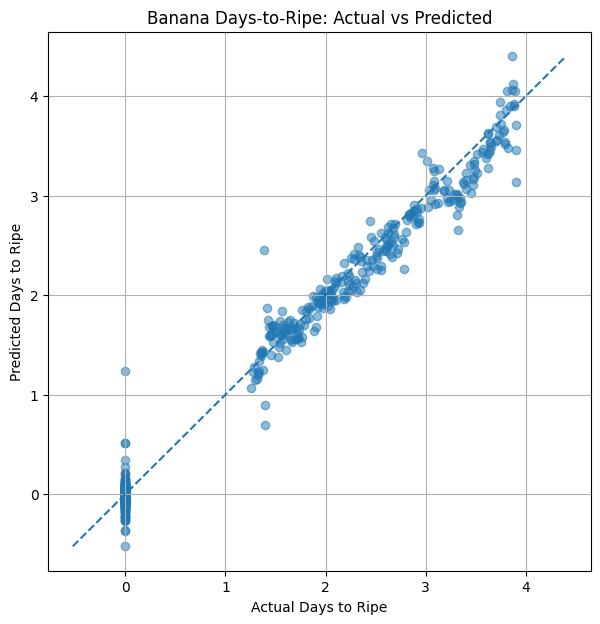

In [ ]:
# ============================================================
# STEP B — ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create results dataframe using the actual column names
error_df = test_df[
    ["Sl_No", "Timestamp_excel", "Ripeness_Label"]
].copy()

error_df["Actual_Days_to_Ripe"] = y_test
error_df["Predicted_Days_to_Ripe"] = test_predictions

error_df["Absolute_Error_Days"] = np.abs(
    error_df["Actual_Days_to_Ripe"]
    - error_df["Predicted_Days_to_Ripe"]
)

error_df["Absolute_Error_Hours"] = (
    error_df["Absolute_Error_Days"] * 24
)

# ------------------------------------------------------------
# 1. Overall statistics
# ------------------------------------------------------------

print("========================================")
print("ERROR ANALYSIS")
print("========================================")

print("\nMean Absolute Error:")
print(f"{error_df['Absolute_Error_Days'].mean():.4f} days")
print(f"{error_df['Absolute_Error_Hours'].mean():.2f} hours")

print("\nMaximum absolute error:")
print(
    f"{error_df['Absolute_Error_Days'].max():.4f} days "
    f"({error_df['Absolute_Error_Hours'].max():.2f} hours)"
)

# ------------------------------------------------------------
# 2. Error by Days-to-Ripe range
# ------------------------------------------------------------

bins = [-0.001, 1, 2, 3, 4]
labels = ["0–1 day", "1–2 days", "2–3 days", "3–4 days"]

error_df["Days_Range"] = pd.cut(
    error_df["Actual_Days_to_Ripe"],
    bins=bins,
    labels=labels
)

range_results = (
    error_df
    .groupby("Days_Range", observed=False)
    .agg(
        Samples=("Actual_Days_to_Ripe", "size"),
        MAE_Days=("Absolute_Error_Days", "mean"),
        MAE_Hours=("Absolute_Error_Hours", "mean")
    )
    .reset_index()
)

print("\n========================================")
print("ERROR BY DAYS-TO-RIPE RANGE")
print("========================================")

print(range_results.to_string(index=False))

# ------------------------------------------------------------
# 3. Worst 15 predictions
# ------------------------------------------------------------

worst_predictions = (
    error_df
    .sort_values("Absolute_Error_Days", ascending=False)
    .head(15)
)

print("\n========================================")
print("15 WORST PREDICTIONS")
print("========================================")

print(
    worst_predictions[
        [
            "Sl_No",
            "Timestamp_excel",
            "Actual_Days_to_Ripe",
            "Predicted_Days_to_Ripe",
            "Absolute_Error_Hours"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 4. Actual vs Predicted plot
# ------------------------------------------------------------

plt.figure(figsize=(7, 7))

plt.scatter(
    error_df["Actual_Days_to_Ripe"],
    error_df["Predicted_Days_to_Ripe"],
    alpha=0.5
)

min_value = min(
    error_df["Actual_Days_to_Ripe"].min(),
    error_df["Predicted_Days_to_Ripe"].min()
)

max_value = max(
    error_df["Actual_Days_to_Ripe"].max(),
    error_df["Predicted_Days_to_Ripe"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Days to Ripe")
plt.ylabel("Predicted Days to Ripe")
plt.title("Banana Days-to-Ripe: Actual vs Predicted")
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# ABLATION STUDY — SENSOR-ONLY MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np

# ------------------------------------------------------------
# 1. Build sensor-only regression model
# ------------------------------------------------------------

sensor_only_input = layers.Input(
    shape=(39,),
    name="sensor_input"
)

x = layers.Dense(128, activation="relu")(sensor_only_input)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.20)(x)

x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.15)(x)

x = layers.Dense(32, activation="relu")(x)

sensor_only_output = layers.Dense(
    1,
    activation="linear",
    name="days_to_ripe"
)(x)

sensor_only_model = Model(
    inputs=sensor_only_input,
    outputs=sensor_only_output,
    name="banana_sensor_only"
)

sensor_only_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="mse",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae"),
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

sensor_only_model.summary()

# ------------------------------------------------------------
# 2. Train
# ------------------------------------------------------------

sensor_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

sensor_history = sensor_only_model.fit(
    X_sensor_train_scaled,
    y_train,
    validation_data=(
        X_sensor_val_scaled,
        y_val
    ),
    epochs=40,
    batch_size=32,
    callbacks=sensor_callbacks,
    verbose=1
)

Model: "banana_sensor_only"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor_input (InputLayer)       │ (None, 39)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ days_to_ripe (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,001 (62.50 KB)

 Trainable params: 15,745 (61.50 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 7.2158 - mae: 2.2271 - rmse: 2.6862 - val_loss: 4.4366 - val_mae: 1.6484 - val_rmse: 2.1063 - learning_rate: 1.0000e-04
Epoch 2/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 3.6510 - mae: 1.5316 - rmse: 1.9108 - val_loss: 2.9308 - val_mae: 1.3175 - val_rmse: 1.7120 - learning_rate: 1.0000e-04
Epoch 3/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.0039 - mae: 1.1109 - rmse: 1.4156 - val_loss: 1.7386 - val_mae: 1.0194 - val_rmse: 1.3186 - learning_rate: 1.0000e-04
Epoch 4/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.2364 - mae: 0.8517 - rmse: 1.1119 - val_loss: 0.9541 - val_mae: 0.7357 - val_rmse: 0.9768 - learning_rate: 1.0000e-04
Epoch 5/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.8875 - mae: 0.7239 - rmse: 0.9421 - val_loss: 0.5477 - val_mae: 0.5415 - val_rmse: 0.7401 - learning_rate: 1.0000e-04
Epoch 6/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.7702 - mae: 0.6581 - rmse: 0.8776 - val_loss: 0.37

In [ ]:
SENSOR_MODEL_PATH = "/content/drive/MyDrive/mmodels/banana_days_to_ripe_sensor_only.keras"

sensor_only_model.save(SENSOR_MODEL_PATH)

print("Saved:", SENSOR_MODEL_PATH)

Saved: /content/drive/MyDrive/mmodels/banana_days_to_ripe_sensor_only.keras


In [ ]:
# ============================================================
# ABLATION STUDY — SENSOR-ONLY TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

sensor_test_predictions = sensor_only_model.predict(
    X_sensor_test_scaled,
    batch_size=32,
    verbose=1
).flatten()

sensor_test_mae = mean_absolute_error(
    y_test,
    sensor_test_predictions
)

sensor_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        sensor_test_predictions
    )
)

sensor_test_r2 = r2_score(
    y_test,
    sensor_test_predictions
)

print("\n========================================")
print("SENSOR-ONLY — TEST RESULTS")
print("========================================")

print(f"MAE  : {sensor_test_mae:.4f} days")
print(f"RMSE : {sensor_test_rmse:.4f} days")
print(f"R²   : {sensor_test_r2:.4f}")

print(
    f"\nMAE in hours: "
    f"{sensor_test_mae * 24:.2f} hours"
)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

SENSOR-ONLY — TEST RESULTS
MAE  : 0.1992 days
RMSE : 0.3292 days
R²   : 0.9417

MAE in hours: 4.78 hours


In [ ]:
# ============================================================
# ABLATION STUDY — IMAGE-ONLY MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model

# ------------------------------------------------------------
# 1. IMAGE BRANCH
# ------------------------------------------------------------

image_only_input = layers.Input(
    shape=(224, 224, 3),
    name="image_input"
)

x = layers.Lambda(
    lambda img: tf.keras.applications.mobilenet_v2.preprocess_input(
        img * 255.0
    )
)(image_only_input)

image_base = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

image_base.trainable = False

x = image_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.30)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.20)(x)

image_only_output = layers.Dense(
    1,
    activation="linear",
    name="days_to_ripe"
)(x)

image_only_model = Model(
    inputs=image_only_input,
    outputs=image_only_output,
    name="banana_image_only"
)

# ------------------------------------------------------------
# 2. COMPILE
# ------------------------------------------------------------

image_only_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="mse",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae"),
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

image_only_model.summary()

# ------------------------------------------------------------
# 3. CALLBACKS
# ------------------------------------------------------------

image_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# ------------------------------------------------------------
# 4. TRAIN
# ------------------------------------------------------------

image_history = image_only_model.fit(
    X_image_train_array,
    y_train,

    validation_data=(
        X_image_val_array,
        y_val
    ),

    epochs=40,
    batch_size=32,

    callbacks=image_callbacks,
    verbose=1
)

Model: "banana_image_only"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ days_to_ripe (Dense)            │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,618,945 (9.99 MB)

 Trainable params: 360,961 (1.38 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - loss: 0.4625 - mae: 0.5173 - rmse: 0.6801 - val_loss: 0.1051 - val_mae: 0.2441 - val_rmse: 0.3242 - learning_rate: 1.0000e-04
Epoch 2/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 151s 2s/step - loss: 0.1960 - mae: 0.3413 - rmse: 0.4427 - val_loss: 0.0559 - val_mae: 0.1770 - val_rmse: 0.2365 - learning_rate: 1.0000e-04
Epoch 3/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - loss: 0.1356 - mae: 0.2783 - rmse: 0.3682 - val_loss: 0.0679 - val_mae: 0.2083 - val_rmse: 0.2606 - learning_rate: 1.0000e-04
Epoch 4/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - loss: 0.1094 - mae: 0.2475 - rmse: 0.3307 - val_loss: 0.0502 - val_mae: 0.1648 - val_rmse: 0.2240 - learning_rate: 1.0000e-04
Epoch 5/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - loss: 0.1009 - mae: 0.2335 - rmse: 0.3176 - val_loss: 0.0631 - val_mae: 0.1918 - val_rmse: 0.2512 - learning_rate: 1.0000e-04
Epoch 6/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - loss: 0.0934 - mae: 0.2188 - rmse: 0.3056 - val_loss

In [ ]:
print("image_only_model" in globals())

if "image_only_model" in globals():
    print(image_only_model.name)

True
banana_image_only


In [ ]:
y_pred_img = image_only_model.predict(
    X_image_test_array,
    batch_size=32,
    verbose=1
).flatten()

# Days-to-ripe cannot be negative
y_pred_img = np.maximum(y_pred_img, 0)

mae_img = mean_absolute_error(y_test, y_pred_img)
rmse_img = np.sqrt(mean_squared_error(y_test, y_pred_img))
r2_img = r2_score(y_test, y_pred_img)

print("\nIMAGE-ONLY TEST RESULTS")
print("=" * 40)
print(f"MAE  : {mae_img:.4f} days")
print(f"MAE  : {mae_img * 24:.2f} hours")
print(f"RMSE : {rmse_img:.4f} days")
print(f"R²   : {r2_img:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step

IMAGE-ONLY TEST RESULTS
MAE  : 0.1024 days
MAE  : 2.46 hours
RMSE : 0.1529 days
R²   : 0.9874


In [ ]:
IMAGE_MODEL_PATH = "/content/drive/MyDrive/CAPSTONE DATASET/mmodels/banana_days_to_ripe_image_only.keras"

image_only_model.save(IMAGE_MODEL_PATH)

print("Saved:", IMAGE_MODEL_PATH)

Saved: /content/drive/MyDrive/CAPSTONE DATASET/mmodels/banana_days_to_ripe_image_only.keras


In [ ]:
SENSOR_MODEL_PATH = "/content/drive/MyDrive/CAPSTONE DATASET/mmodels/banana_days_to_ripe_sensor_only.keras"

sensor_only_model.save(SENSOR_MODEL_PATH)

print("Saved:", SENSOR_MODEL_PATH)

Saved: /content/drive/MyDrive/CAPSTONE DATASET/mmodels/banana_days_to_ripe_sensor_only.keras


In [ ]:
import os

base = "/content/drive/MyDrive/CAPSTONE DATASET"

# Folders to completely exclude
exclude_folders = {"DEMO_MODEL_codes"}

# Folders to show but NOT show their contents
hide_contents = {"Original_Images", "Processed_Images"}

def print_tree(path, prefix=""):
    items = sorted(os.listdir(path))

    for i, item in enumerate(items):
        full_path = os.path.join(path, item)
        is_last = i == len(items) - 1
        branch = "└── " if is_last else "├── "

        if os.path.isdir(full_path):

            # Completely skip DEMO_MODEL_codes
            if item in exclude_folders:
                continue

            print(prefix + branch + "📁 " + item + "/")

            # Show folder but don't enter it
            if item in hide_contents:
                continue

            new_prefix = prefix + ("    " if is_last else "│   ")
            print_tree(full_path, new_prefix)

        else:
            print(prefix + branch + "📄 " + item)

print("📁 CAPSTONE DATASET/")
print_tree(base)

📁 CAPSTONE DATASET/
├── 📁 3-10-26/
│   └── 📄 Original_sensor_data_labeled.xlsx
├── 📁 Original_Images/
├── 📄 Original_sensor_data.xlsx
├── 📁 Processed_Images/
├── 📁 feature_engineered_data/
│   └── 📄 sensor_features.csv
├── 📁 mmodels/
│   ├── 📄 banana_days_to_ripe_image_only.keras
│   ├── 📄 banana_days_to_ripe_image_only_portable.keras
│   ├── 📄 banana_days_to_ripe_multimodal_baseline.keras
│   ├── 📄 banana_days_to_ripe_multimodal_portable.keras
│   ├── 📄 banana_days_to_ripe_sensor_only.keras
│   ├── 📄 banana_days_to_ripe_sensor_only_portable.keras
│   └── 📄 banana_ripeness_4class.keras
├── 📁 notebooks/
│   ├── 📄 01sensor_preprocessing.ipynb
│   ├── 📄 02_sensor_feature_engineering.ipynb
│   └── 📄 ImagePreprocessing.ipynb
└── 📁 processed_data/
    └── 📄 sensor_preprocessed.csv


In [ ]:
# ============================================================
# BANANA DAYS-TO-RIPE - FINAL INTERFACE
# ============================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets


# ============================================================
# 1. PATHS
# ============================================================

MODEL_DIR = "/content/drive/MyDrive/CAPSTONE DATASET/mmodels"

IMAGE_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "banana_days_to_ripe_image_only_portable.keras"
)

MULTIMODAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "banana_days_to_ripe_multimodal_portable.keras"
)


# ============================================================
# 2. LOAD TRAINED MODELS
# ============================================================

print("=" * 70)
print("LOADING BANANA DAYS-TO-RIPE MODELS")
print("=" * 70)

# Image-only model
image_model = tf.keras.models.load_model(
    IMAGE_MODEL_PATH,
    safe_mode=True,
    compile=False
)

# Final multimodal model
multimodal_model = tf.keras.models.load_model(
    MULTIMODAL_MODEL_PATH,
    safe_mode=True,
    compile=False
)

print()
print("Image-only model loaded:")
print(image_model.name)

print()
print("Multimodal model loaded:")
print(multimodal_model.name)

print()
print("Models loaded successfully.")


# ============================================================
# 3. BASIC DATA CHECK
# ============================================================

print()
print("=" * 70)
print("CHECKING TEST DATA")
print("=" * 70)

print("Test image shape :", X_image_test_array.shape)
print("Test sensor shape:", X_sensor_test_scaled.shape)
print("Test target shape:", np.asarray(y_test).shape)

assert len(X_image_test_array) == len(X_sensor_test_scaled)
assert len(X_image_test_array) == len(y_test)

print("Test datasets are aligned.")


# ============================================================
# 4. SENSOR FEATURE INFORMATION
# ============================================================

categorical_columns = [
    "Temperature_Level",
    "Humidity_Level",
    "Gas_Level"
]

numeric_columns = [
    c for c in X_sensor_train.columns
    if c not in categorical_columns
]

print()
print("Numeric sensor features    :", len(numeric_columns))
print("Categorical sensor features:", len(categorical_columns))

assert len(numeric_columns) == 33


# ============================================================
# 5. IMAGE PREPARATION
# ============================================================

def prepare_image_for_model(image):

    if isinstance(image, str):
        image = Image.open(image)

    image = image.convert("RGB")
    image = image.resize((224, 224))

    arr = np.asarray(image).astype(np.float32) / 255.0

    return np.expand_dims(arr, axis=0)


def prepare_uploaded_image(file_bytes):

    from io import BytesIO

    image = Image.open(
        BytesIO(file_bytes)
    ).convert("RGB")

    return image


# ============================================================
# 6. LIVE SENSOR FEATURE CREATION
# ============================================================

def create_live_sensor_features(
    temperature,
    humidity,
    gas
):
    """
    Temporary live-input preprocessing.

    The trained sensor branch expects:
        33 numeric features
        +
        6 one-hot categorical features
        =
        39 features

    Because live mode currently receives only T/H/G,
    the remaining engineered features are obtained from
    the closest historical sensor context.

    This is for interface testing only.

    Final Raspberry Pi deployment will use rolling
    sensor history and the exact feature-engineering
    pipeline.
    """

    historical = X_sensor_train.copy()

    # --------------------------------------------------------
    # Find closest historical T/H/G context
    # --------------------------------------------------------

    temperature_std = max(
        historical["Temperature_excel"].std(),
        1e-6
    )

    humidity_std = max(
        historical["Humidity_excel"].std(),
        1e-6
    )

    gas_std = max(
        historical["Gas_excel"].std(),
        1e-6
    )

    distances = (
        ((historical["Temperature_excel"] - temperature)
         / temperature_std) ** 2
        +
        ((historical["Humidity_excel"] - humidity)
         / humidity_std) ** 2
        +
        ((historical["Gas_excel"] - gas)
         / gas_std) ** 2
    )

    nearest_idx = distances.idxmin()

    row = historical.loc[nearest_idx].copy()

    # Replace raw values with live readings
    row["Temperature_excel"] = temperature
    row["Humidity_excel"] = humidity
    row["Gas_excel"] = gas

    # --------------------------------------------------------
    # 33 numeric features
    # --------------------------------------------------------

    numeric_df = pd.DataFrame(
        [row[numeric_columns].values],
        columns=numeric_columns
    )

    numeric_df.loc[0, "Temperature_excel"] = temperature
    numeric_df.loc[0, "Humidity_excel"] = humidity
    numeric_df.loc[0, "Gas_excel"] = gas

    numeric_scaled = sensor_scaler.transform(
        numeric_df
    ).astype(np.float32)

    # --------------------------------------------------------
    # 6 categorical features
    # --------------------------------------------------------

    categorical_df = pd.DataFrame({
        "Humidity_Level": [
            row["Humidity_Level"]
        ],
        "Gas_Level": [
            row["Gas_Level"]
        ]
    })

    categorical_encoded = categorical_encoder.transform(
        categorical_df
    )

    if hasattr(categorical_encoded, "toarray"):
        categorical_encoded = categorical_encoded.toarray()

    categorical_encoded = np.asarray(
        categorical_encoded,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Combine
    # 33 numeric + 6 categorical = 39
    # --------------------------------------------------------

    combined = np.concatenate(
        [
            numeric_scaled,
            categorical_encoded
        ],
        axis=1
    ).astype(np.float32)

    # --------------------------------------------------------
    # Safety checks
    # --------------------------------------------------------

    assert numeric_scaled.shape == (1, 33)
    assert categorical_encoded.shape == (1, 6)
    assert combined.shape == (1, 39)

    return combined, nearest_idx


# ============================================================
# 7. MODEL PREDICTION
# ============================================================

def predict_models(
    image_array,
    sensor_array
):
    """
    IMPORTANT:

    Image-only:
        image -> trained image model -> prediction

    Multimodal:
        image -> image branch
        sensor -> sensor branch
        image features + sensor features
            -> concatenation
            -> fusion layers
            -> prediction

    Direct model calls are used instead of model.predict()
    to avoid repeated TensorFlow prediction-function tracing.
    """

    # --------------------------------------------------------
    # Image-only
    # --------------------------------------------------------

    image_prediction = image_model(
        image_array,
        training=False
    ).numpy()[0][0]

    # --------------------------------------------------------
    # Multimodal
    # --------------------------------------------------------

    multimodal_prediction = multimodal_model(
        [
            image_array,
            sensor_array
        ],
        training=False
    ).numpy()[0][0]

    # --------------------------------------------------------
    # Physical constraint
    # --------------------------------------------------------

    image_prediction = max(
        0.0,
        float(image_prediction)
    )

    multimodal_prediction = max(
        0.0,
        float(multimodal_prediction)
    )

    return {
        "Image-only": image_prediction,
        "Multimodal": multimodal_prediction
    }


# ============================================================
# 8. TEST RESULT DISPLAY
# ============================================================

def display_test_results(
    predictions,
    actual,
    temperature,
    humidity,
    gas
):

    print()
    print("=" * 72)
    print("BANANA DAYS-TO-RIPE PREDICTION")
    print("=" * 72)

    print(
        f"Temperature : {temperature:.2f} °C"
    )

    print(
        f"Humidity    : {humidity:.2f} %"
    )

    print(
        f"Gas         : {gas:.2f}"
    )

    print()
    print(
        f"{'Model':<20}"
        f"{'Prediction':>18}"
        f"{'Actual':>18}"
        f"{'Abs Error':>18}"
    )

    print("-" * 74)

    for model_name, prediction in predictions.items():

        error = abs(
            prediction - actual
        )

        print(
            f"{model_name:<20}"
            f"{prediction:>15.3f} d"
            f"{actual:>15.3f} d"
            f"{error:>15.3f} d"
        )

    print("-" * 74)

    print()
    print(
        f"Actual Days-to-Ripe: {actual:.3f} days"
    )


# ============================================================
# 9. LIVE RESULT DISPLAY
# ============================================================

def display_live_results(
    predictions,
    temperature,
    humidity,
    gas
):

    print()
    print("=" * 72)
    print("BANANA LIVE DAYS-TO-RIPE PREDICTION")
    print("=" * 72)

    print(
        f"Temperature : {temperature:.2f} °C"
    )

    print(
        f"Humidity    : {humidity:.2f} %"
    )

    print(
        f"Gas         : {gas:.2f}"
    )

    print()
    print("-" * 72)

    # --------------------------------------------------------
    # Image-only comparison
    # --------------------------------------------------------

    image_days = max(
        0,
        int(round(predictions["Image-only"]))
    )

    print(
        f"Image-only prediction : {image_days} days"
    )

    # --------------------------------------------------------
    # Final multimodal result
    # --------------------------------------------------------

    multimodal_days = max(
        0,
        int(round(predictions["Multimodal"]))
    )

    print(
        f"Multimodal prediction : {multimodal_days} days"
    )

    print("-" * 72)

    print()
    print(
        f"FINAL DAYS UNTIL RIPE: {multimodal_days} DAYS"
    )


# ============================================================
# 10. TEST DATA MODE
# ============================================================

test_index = widgets.IntSlider(
    value=0,
    min=0,
    max=len(X_image_test_array) - 1,
    step=1,
    description="Test sample:",
    continuous_update=False,
    style={
        "description_width": "initial"
    },
    layout=widgets.Layout(
        width="600px"
    )
)


test_button = widgets.Button(
    description="Predict Test Sample",
    button_style="primary",
    layout=widgets.Layout(
        width="220px"
    )
)


test_output = widgets.Output()


def run_test_prediction(button):

    with test_output:

        clear_output(wait=True)

        idx = test_index.value

        # ----------------------------------------------------
        # Image
        # ----------------------------------------------------

        image_array = X_image_test_array[
            idx:idx + 1
        ]

        # ----------------------------------------------------
        # Sensor
        # ----------------------------------------------------

        sensor_array = X_sensor_test_scaled[
            idx:idx + 1
        ]

        # ----------------------------------------------------
        # Raw T/H/G
        # ----------------------------------------------------

        raw_sensor = X_sensor_test.iloc[idx]

        temperature = float(
            raw_sensor["Temperature_excel"]
        )

        humidity = float(
            raw_sensor["Humidity_excel"]
        )

        gas = float(
            raw_sensor["Gas_excel"]
        )

        # ----------------------------------------------------
        # Actual target
        # ----------------------------------------------------

        actual = float(
            np.asarray(y_test)[idx]
        )

        # ----------------------------------------------------
        # Predictions
        # ----------------------------------------------------

        predictions = predict_models(
            image_array,
            sensor_array
        )

        # ----------------------------------------------------
        # Display image
        # ----------------------------------------------------

        plt.figure(figsize=(5, 5))

        plt.imshow(
            image_array[0]
        )

        plt.axis("off")

        plt.title(
            f"Test Sample {idx}"
        )

        plt.show()

        # ----------------------------------------------------
        # Results
        # ----------------------------------------------------

        display_test_results(
            predictions,
            actual,
            temperature,
            humidity,
            gas
        )


test_button.on_click(
    run_test_prediction
)


# ============================================================
# 11. LIVE INPUT MODE
# ============================================================

upload_widget = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload Banana"
)


temperature_widget = widgets.FloatText(
    value=28.0,
    description="Temperature °C:",
    style={
        "description_width": "initial"
    }
)


humidity_widget = widgets.FloatText(
    value=58.0,
    description="Humidity %:",
    style={
        "description_width": "initial"
    }
)


gas_widget = widgets.FloatText(
    value=150.0,
    description="Gas:",
    style={
        "description_width": "initial"
    }
)


live_button = widgets.Button(
    description="Predict Live Input",
    button_style="success",
    layout=widgets.Layout(
        width="220px"
    )
)


live_output = widgets.Output()


def get_uploaded_file_bytes():

    if not upload_widget.value:
        return None

    value = upload_widget.value

    # Newer ipywidgets
    if isinstance(value, dict):

        first_file = next(
            iter(value.values())
        )

        return first_file["content"]

    # Older ipywidgets
    if isinstance(value, tuple):

        first_file = value[0]

        if isinstance(first_file, dict):
            return first_file["content"]

        return first_file.content

    return None


def run_live_prediction(button):

    with live_output:

        clear_output(wait=True)

        # ----------------------------------------------------
        # Check image
        # ----------------------------------------------------

        file_bytes = get_uploaded_file_bytes()

        if file_bytes is None:

            print(
                "Please upload a banana image first."
            )

            return

        # ----------------------------------------------------
        # Sensor values
        # ----------------------------------------------------

        temperature = float(
            temperature_widget.value
        )

        humidity = float(
            humidity_widget.value
        )

        gas = float(
            gas_widget.value
        )

        # ----------------------------------------------------
        # Prepare image
        # ----------------------------------------------------

        image = prepare_uploaded_image(
            file_bytes
        )

        image_array = prepare_image_for_model(
            image
        )

        # ----------------------------------------------------
        # Prepare sensor features
        # ----------------------------------------------------

        sensor_array, nearest_idx = (
            create_live_sensor_features(
                temperature,
                humidity,
                gas
            )
        )

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        predictions = predict_models(
            image_array,
            sensor_array
        )

        # ----------------------------------------------------
        # Display uploaded image
        # ----------------------------------------------------

        plt.figure(figsize=(5, 5))

        plt.imshow(image)

        plt.axis("off")

        plt.title(
            "Live Banana Input"
        )

        plt.show()

        # ----------------------------------------------------
        # LIVE RESULT
        # ----------------------------------------------------

        display_live_results(
            predictions,
            temperature,
            humidity,
            gas
        )

        # ----------------------------------------------------
        # Temporary development information
        # ----------------------------------------------------

        print()
        print(
            f"Temporary sensor context row: {nearest_idx}"
        )

        print(
            "Note: Live sensor features currently use "
            "historical context because only T/H/G are entered."
        )


live_button.on_click(
    run_live_prediction
)


# ============================================================
# 12. INTERFACE LAYOUT
# ============================================================

test_tab = widgets.VBox([
    widgets.HTML(
        "<h3>Test Data Mode</h3>"
    ),
    test_index,
    test_button,
    test_output
])


live_tab = widgets.VBox([
    widgets.HTML(
        "<h3>Live Input Mode</h3>"
    ),
    upload_widget,
    temperature_widget,
    humidity_widget,
    gas_widget,
    live_button,
    live_output
])


interface = widgets.Tab(
    children=[
        test_tab,
        live_tab
    ]
)


interface.set_title(
    0,
    "Test Data"
)

interface.set_title(
    1,
    "Live Input"
)


display(interface)

print()
print("=" * 72)
print("INTERFACE READY")
print("=" * 72)

LOADING BANANA DAYS-TO-RIPE MODELS

Image-only model loaded:
banana_image_only_portable

Multimodal model loaded:
banana_days_to_ripe_multimodal_portable

Models loaded successfully.

CHECKING TEST DATA
Test image shape : (498, 224, 224, 3)
Test sensor shape: (498, 39)
Test target shape: (498,)
Test datasets are aligned.

Numeric sensor features    : 33
Categorical sensor features: 3



INTERFACE READY


## Export the fitted live-input preprocessing objects

Run this cell after the model data-preparation cells have created `sensor_scaler`, `categorical_encoder`, `numeric_columns`, and `X_sensor_train`. It saves the exact fitted transforms and historical context used by `create_live_sensor_features` so the Pi preprocessing notebook can reproduce the same 39-value vector. `X_sensor_train` context is retained because the current notebook?s live-input method selects its nearest historical T/H/G row. This preserves the existing demo behavior; it is not a replacement for engineering true rolling live history.

Copy the resulting `raw_to_ripe_preprocessing.pkl` into the project's `my files` folder.

In [ ]:
# EXPORT_RAW_TO_RIPE_PREPROCESSOR
from pathlib import Path
import pickle

required = ["sensor_scaler", "categorical_encoder", "numeric_columns", "X_sensor_train"]
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(f"Run the feature preparation cells first; missing: {missing}")
if len(numeric_columns) != 33 or int(sensor_scaler.n_features_in_) != 33:
    raise ValueError(
        f"Expected 33 scaled numeric features, found columns={len(numeric_columns)} "
        f"and scaler features={sensor_scaler.n_features_in_}"
    )
required_context = {"Temperature_excel", "Humidity_excel", "Gas_excel", "Humidity_Level", "Gas_Level"}
missing_context = required_context - set(X_sensor_train.columns)
if missing_context:
    raise ValueError(f"Training context is missing required columns: {sorted(missing_context)}")
encoded_width = sum(len(categories) for categories in categorical_encoder.categories_)
if encoded_width != 6:
    raise ValueError(f"Expected 6 one-hot category outputs, found {encoded_width}")
export_path = Path("/content/drive/MyDrive/CAPSTONE DATASET/mmodels/raw_to_ripe_preprocessing.pkl")
export_path.parent.mkdir(parents=True, exist_ok=True)
with export_path.open("wb") as f:
    pickle.dump({
        "sensor_scaler": sensor_scaler,
        "categorical_encoder": categorical_encoder,
        "numeric_columns": list(numeric_columns),
        "context": X_sensor_train.copy(),
        "context_raw_columns": list(X_sensor_train.columns),
    }, f)
print("Saved fitted raw-to-ripe preprocessing bundle:", export_path)